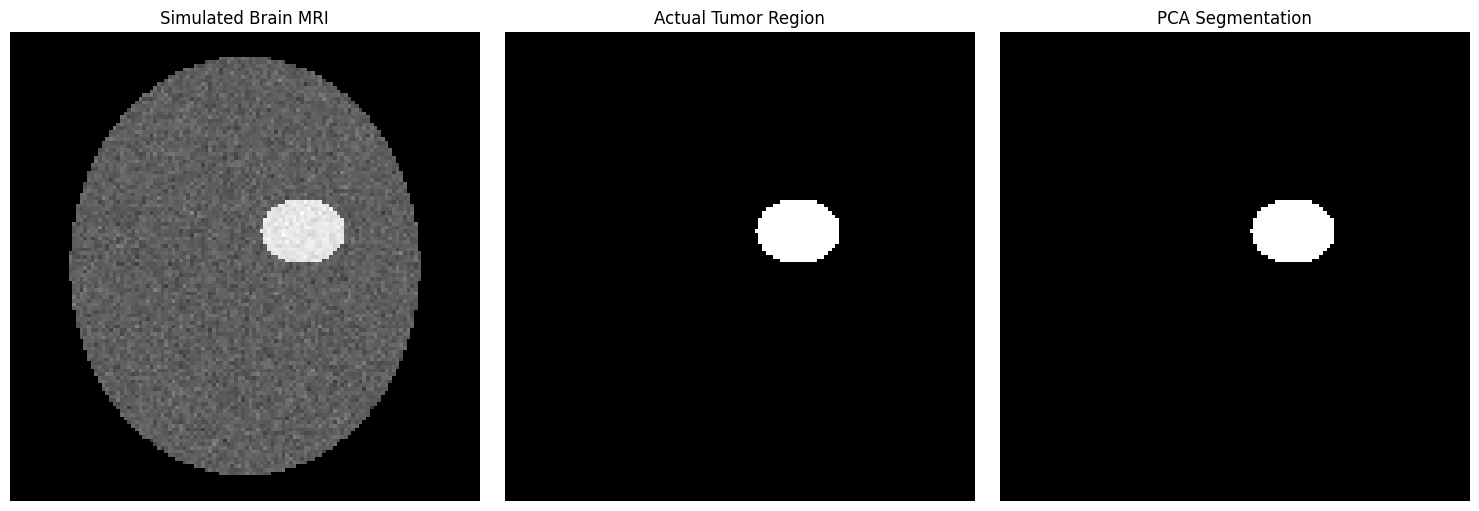

PARALLEL CELLULAR ALGORITHM RESULTS
-----------------------------------
Image Size: (128, 128)
Number of Iterations: 20
Execution Time: 0.00152 seconds
Segmented Pixels: 315
Tumor Pixels: 315
Dice Score: 1.0
IoU Score: 1.0


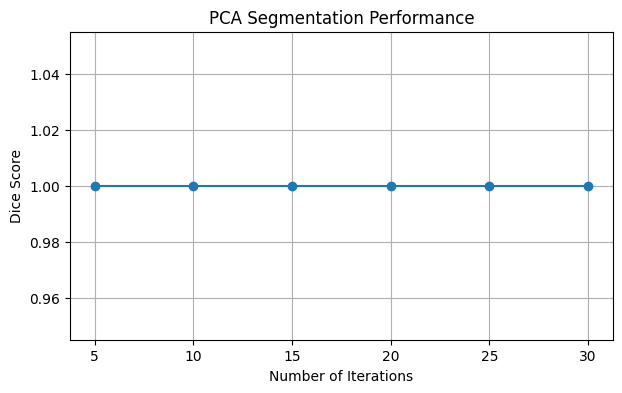

In [11]:
# Parallel Cellular Algorithm for Brain Tumor Segmentation

import numpy as np
import matplotlib.pyplot as plt
import time

# ==========================================
# 1. GENERATE A SIMULATED MRI IMAGE
# ==========================================

np.random.seed(42)

size = 128
x, y = np.meshgrid(
    np.linspace(-1, 1, size),
    np.linspace(-1, 1, size)
)

# Simulated brain-shaped region
brain = (x**2 / 0.75**2 + y**2 / 0.9**2) <= 1

# Background and brain tissue
image = np.zeros((size, size))
image[brain] = 0.35 + np.random.normal(0, 0.04, np.sum(brain))

# Simulated tumour region
tumor = ((x - 0.25)**2 / 0.18**2 +
         (y + 0.15)**2 / 0.14**2) <= 1

image[tumor] = 0.85 + np.random.normal(0, 0.03, np.sum(tumor))

image = np.clip(image, 0, 1)

# ==========================================
# 2. INITIALIZE CELLULAR GRID
# ==========================================

threshold = 0.65

cells = (image >= threshold).astype(np.uint8)

# ==========================================
# 3. PARALLEL CELLULAR ALGORITHM
# ==========================================

def run_pca(image, cells, iterations=20):

    current = cells.copy()
    rows, cols = current.shape

    for iteration in range(iterations):

        padded = np.pad(current, 1, mode="constant")

        neighbors = np.zeros((rows, cols), dtype=np.uint8)

        # Check 8 neighboring cells
        for i in range(3):
            for j in range(3):

                if i == 1 and j == 1:
                    continue

                neighbors += padded[
                    i:i + rows,
                    j:j + cols
                ]

        # Parallel cell state update
        new_cells = (
            (image >= threshold) &
            (neighbors >= 2)
        ).astype(np.uint8)

        current = new_cells

    return current


# ==========================================
# 4. EXECUTE PCA
# ==========================================

start = time.time()

segmented = run_pca(image, cells, iterations=20)

execution_time = time.time() - start

# ==========================================
# 5. EVALUATION
# ==========================================

# Ground truth is available because this is a simulated image
intersection = np.sum(segmented * tumor)
dice = (2 * intersection) / (
    np.sum(segmented) + np.sum(tumor) + 1e-8
)

union = np.sum((segmented + tumor) > 0)
iou = intersection / (union + 1e-8)

# ==========================================
# 6. DISPLAY RESULTS
# ==========================================

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Simulated Brain MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tumor, cmap="gray")
plt.title("Actual Tumor Region")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(segmented, cmap="gray")
plt.title("PCA Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

# ==========================================
# 7. PERFORMANCE RESULTS
# ==========================================

print("PARALLEL CELLULAR ALGORITHM RESULTS")
print("-----------------------------------")
print("Image Size:", image.shape)
print("Number of Iterations:", 20)
print("Execution Time:", round(execution_time, 5), "seconds")
print("Segmented Pixels:", np.sum(segmented))
print("Tumor Pixels:", np.sum(tumor))
print("Dice Score:", round(dice, 4))
print("IoU Score:", round(iou, 4))

# ==========================================
# 8. ITERATION PERFORMANCE GRAPH
# ==========================================

iteration_values = [5, 10, 15, 20, 25, 30]
dice_values = []

for n in iteration_values:
    result = run_pca(image, cells, iterations=n)

    inter = np.sum(result * tumor)
    score = (2 * inter) / (
        np.sum(result) + np.sum(tumor) + 1e-8
    )

    dice_values.append(score)

plt.figure(figsize=(7, 4))
plt.plot(iteration_values, dice_values, marker="o")
plt.xlabel("Number of Iterations")
plt.ylabel("Dice Score")
plt.title("PCA Segmentation Performance")
plt.grid(True)
plt.show()